# DAGs, d-separation and do-calculus, as code

**Question:** every estimator so far assumed conditional ignorability, $\{Y(0), Y(1)\} \perp\!\!\!\perp T \mid X$. *Which*
$X$? Should we adjust for every variable we have? This notebook answers with Pearl's structural causal models: write the
assumptions as a graph, then read off which adjustments identify the effect, and check every claim by simulation.

| § | Idea | Lecture |
|---|---|---|
| 1 | Three building blocks: mediator, confounder, collider | DAGs and SCMs |
| 2 | $E[Y \mid T]$ vs $E[Y \mid do(T)]$ on the hospital | the do operator |
| 3 | Open and blocked paths, d-separation on a 9-node graph | backdoor criterion |
| 4 | The backdoor criterion: every valid adjustment set gives the same answer, invalid ones do not | backdoor criterion |
| 5 | The three rules of do-calculus, and the front-door formula they produce | do-calculus |
| 6 | Same observations, different interventions | ladder of causation |
| 7 | Counterfactuals, PN / PS / PNS, and bounds from experiments | ladder of causation |

Code: [`src/dag.py`](../src/dag.py) (paths, d-separation, backdoor sets, graph surgery),
[`src/docalc.py`](../src/docalc.py) (the three rules), [`src/scm.py`](../src/scm.py) (sampling, `do`, counterfactuals).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt

from src.dag import DAG
from src import docalc
from src.scm import SCM, bernoulli, uniform, probabilities_of_causation, pns_bounds

plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(0)

def corr(a, b):
    return np.corrcoef(a, b)[0, 1]

def partial_corr(a, b, c):
    """Correlation of a and b after linearly regressing out c."""
    C = np.column_stack([np.ones_like(c), c])
    ra = a - C @ np.linalg.lstsq(C, a, rcond=None)[0]
    rb = b - C @ np.linalg.lstsq(C, b, rcond=None)[0]
    return corr(ra, rb)

## 1. Three building blocks

With three nodes there are three ways for association to flow between $T$ and $Y$. Simulate each as a linear SCM with
Gaussian noise and measure the correlation of $T$ and $Y$, marginally and after conditioning on the middle node.

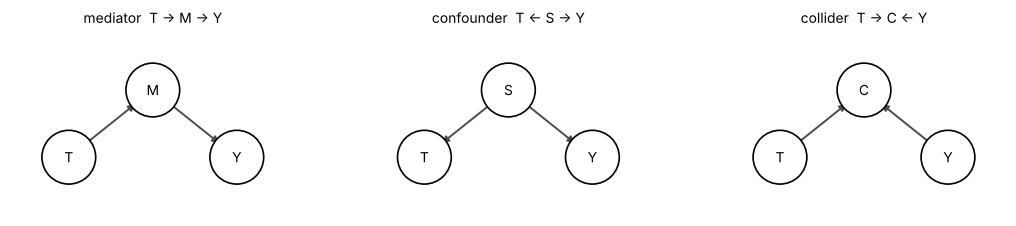

                   pattern | corr(T, Y) | corr(T, Y | middle) | d-separated given middle?
     mediator  T -> M -> Y |      0.578 |              -0.003 | True
   confounder  T <- S -> Y |      0.500 |              -0.002 | True
     collider  T -> C <- Y |     -0.002 |              -0.500 | False


In [2]:
n = 50_000
u = {k: rng.normal(size=n) for k in "TMSYC"}
chain_T = u["T"]; chain_M = chain_T + u["M"]; chain_Y = chain_M + u["Y"]
fork_S = u["S"]; fork_T = fork_S + u["T"]; fork_Y = fork_S + u["Y"]
col_T = u["T"]; col_Y = u["Y"]; col_C = col_T + col_Y + u["C"]

graphs = [("mediator  T -> M -> Y", DAG([("T", "M"), ("M", "Y")]), "M", chain_T, chain_Y, chain_M),
          ("confounder  T <- S -> Y", DAG([("S", "T"), ("S", "Y")]), "S", fork_T, fork_Y, fork_S),
          ("collider  T -> C <- Y", DAG([("T", "C"), ("Y", "C")]), "C", col_T, col_Y, col_C)]
pos = {"T": (0, 0), "Y": (2, 0), "M": (1, 0.8), "S": (1, 0.8), "C": (1, 0.8)}
fig, axes = plt.subplots(1, 3, figsize=(13, 2.4))
for ax, (title, G, mid, t, y, m) in zip(axes, graphs):
    G.draw(ax, {k: pos[k] for k in G.nodes}, title=title)
plt.show()
print(f"{'pattern':>26} | {'corr(T, Y)':>10} | {'corr(T, Y | middle)':>19} | d-separated given middle?")
for title, G, mid, t, y, m in graphs:
    print(f"{title:>26} | {corr(t, y):>10.3f} | {partial_corr(t, y, m):>19.3f} | {G.d_separated('T', 'Y', {mid})}")

Conditioning on a mediator or a confounder **blocks** the path; conditioning on a collider **opens** it. The collider
row is the surprising one: $T$ and $Y$ are independent, yet among units with a given $C$ they are strongly correlated
(two independent dice, conditioned on their sum). Adjusting for "everything" can create bias.

## 2. Observation is not intervention

The hospital as an SCM: $S \to T$, $S \to Y$, $T \to Y$. The `do` operator replaces the equation for $T$ by a constant
and leaves everything else alone; in the graph it deletes the arrows into $T$. Compare three numbers for $t \in \{0,1\}$:
the observational mean $E[Y|T=t]$, the interventional mean $E[Y|do(T=t)]$ (simulated by actually intervening), and the
backdoor formula $\sum_s E[Y|T=t,S=s] P(S=s)$ computed from observational data only.

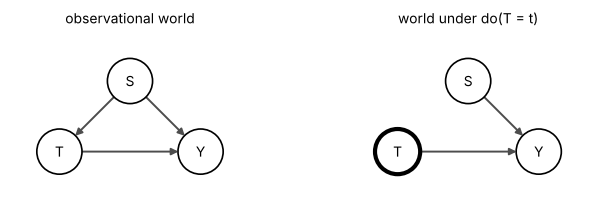

t = 0:  E[Y|T=t] = 0.676   E[Y|do(T=t)] = 0.550   backdoor formula = 0.551
t = 1:  E[Y|T=t] = 0.614   E[Y|do(T=t)] = 0.650   backdoor formula = 0.650


In [3]:
sig = lambda z: 1 / (1 + np.exp(-z))
hospital = SCM(
    equations={
        "S": lambda v, u: 2 * u,                                   # severity ~ U(0, 2)
        "T": lambda v, u: (u < sig(3 * (v["S"] - 1))).astype(float),
        "Y": lambda v, u: 0.9 - 0.35 * v["S"] + v["T"] * (-0.15 + 0.25 * v["S"]) + 0.1 * u,
    },
    noise={"S": uniform(), "T": uniform(), "Y": lambda r, n: r.normal(size=n)},
)
obs = hospital.sample(200_000, seed=1)
G = DAG([("S", "T"), ("S", "Y"), ("T", "Y")])
fig, axes = plt.subplots(1, 2, figsize=(8, 2.2))
P = {"S": (1, 1), "T": (0, 0), "Y": (2, 0)}
G.draw(axes[0], P, title="observational world"); G.do("T").draw(axes[1], P, do={"T"}, title="world under do(T = t)")
plt.show()

bins = np.minimum((obs["S"] * 10).astype(int), 19)
for t in (0, 1):
    observational = obs["Y"][obs["T"] == t].mean()
    interventional = hospital.sample(200_000, do={"T": t}, seed=2)["Y"].mean()
    backdoor = sum(obs["Y"][(obs["T"] == t) & (bins == b)].mean() * (bins == b).mean() for b in range(20))
    print(f"t = {t}:  E[Y|T=t] = {observational:.3f}   E[Y|do(T=t)] = {interventional:.3f}   backdoor formula = {backdoor:.3f}")

The backdoor formula, computed only from observational data, matches the interventional means up to binning error,
while the observational means do not. This is the conditioning estimator of the potential-outcomes lectures, now
*derived* from the graph: $E[Y(t)] = E[Y | do(T=t)]$.

## 3. Paths and d-separation

A larger graph, in the spirit of the lecture's example: $T$ affects $Y$ directly and through a mediator $M_1$; there
are confounders, a collider $W_5$ between two of them, and a descendant $W_6$ of the collider.

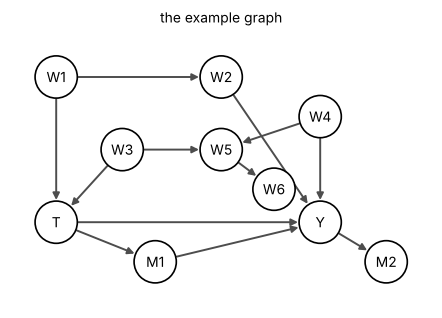

Z = {}  -> paths between T and Y:
   OPEN     T -> Y
   OPEN     T -> M1 -> Y
   OPEN     T <- W1 -> W2 -> Y
   blocked  T <- W3 -> W5 <- W4 -> Y
Z = ['W1']  -> paths between T and Y:
   OPEN     T -> Y
   OPEN     T -> M1 -> Y
   blocked  T <- W1 -> W2 -> Y
   blocked  T <- W3 -> W5 <- W4 -> Y
Z = ['W2']  -> paths between T and Y:
   OPEN     T -> Y
   OPEN     T -> M1 -> Y
   blocked  T <- W1 -> W2 -> Y
   blocked  T <- W3 -> W5 <- W4 -> Y
Z = ['W1', 'W5']  -> paths between T and Y:
   OPEN     T -> Y
   OPEN     T -> M1 -> Y
   blocked  T <- W1 -> W2 -> Y
   OPEN     T <- W3 -> W5 <- W4 -> Y
Z = ['W1', 'W6']  -> paths between T and Y:
   OPEN     T -> Y
   OPEN     T -> M1 -> Y
   blocked  T <- W1 -> W2 -> Y
   OPEN     T <- W3 -> W5 <- W4 -> Y
Z = ['W1', 'W4', 'W5']  -> paths between T and Y:
   OPEN     T -> Y
   OPEN     T -> M1 -> Y
   blocked  T <- W1 -> W2 -> Y
   blocked  T <- W3 -> W5 <- W4 -> Y


In [4]:
edges = [("W1", "T"), ("W1", "W2"), ("W2", "Y"),          # backdoor path T <- W1 -> W2 -> Y
         ("W3", "T"), ("W3", "W5"), ("W4", "W5"), ("W4", "Y"),   # T <- W3 -> W5 <- W4 -> Y (blocked at the collider)
         ("W5", "W6"),
         ("T", "M1"), ("M1", "Y"), ("T", "Y"), ("Y", "M2")]
G = DAG(edges)
pos = {"W1": (0, 2.2), "W2": (2.5, 2.2), "W3": (1, 1.1), "W5": (2.5, 1.1), "W4": (4, 1.6), "W6": (3.3, 0.5),
       "T": (0, 0), "M1": (1.5, -0.6), "Y": (4, 0), "M2": (5, -0.6)}
fig, ax = plt.subplots(figsize=(7, 3.6)); G.draw(ax, pos, title="the example graph"); plt.show()
for Z in [set(), {"W1"}, {"W2"}, {"W1", "W5"}, {"W1", "W6"}, {"W1", "W4", "W5"}]:
    print(f"Z = {sorted(Z) or '{}'}  -> paths between T and Y:")
    print("   " + G.explain("T", "Y", Z).replace("\n", "\n   "))

Read the list for $Z = \{W_1, W_5\}$: conditioning on the collider $W_5$ opens $T \leftarrow W_3 \to W_5 \leftarrow
W_4 \to Y$, and conditioning on its descendant $W_6$ does too. Adding $W_4$ closes it again.

## 4. The backdoor criterion, checked by regression

$Z$ satisfies the backdoor criterion for $(T, Y)$ if it blocks every path that starts with an arrow into $T$ and
contains no descendant of $T$. Then $E[Y | do(T)] = \sum_z E[Y|T, Z=z]P(z)$, and for a linear SCM the coefficient of
$T$ in $Y \sim T + Z$ is the total causal effect.

Below: simulate the graph as a linear SCM with random coefficients, compute the true total effect of $T$ on $Y$
(direct + through $M_1$), then run the regression for *every* subset of the other observed variables.

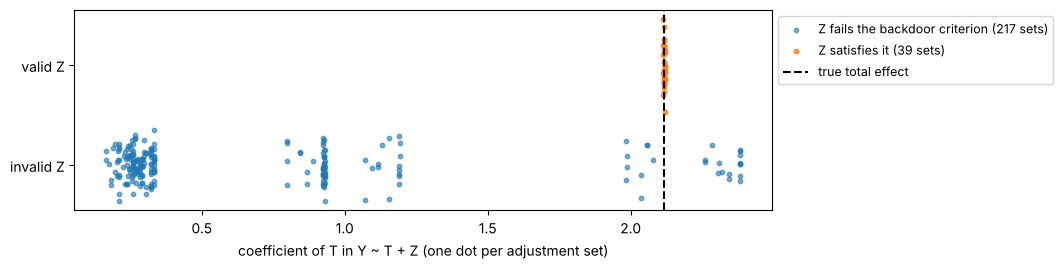

true total effect 2.115; valid sets give 2.114 .. 2.121
minimal valid adjustment sets: [['W1'], ['W2']]


In [5]:
from itertools import combinations
order = G.topological_order()
coef = {e: rng.uniform(0.5, 1.5) for e in sorted(G.edges)}
def simulate_linear(n, do=None, seed=0):
    r = np.random.default_rng(seed); vals = {}
    for v in order:
        if do and v in do:
            vals[v] = np.full(n, do[v]); continue
        vals[v] = sum(coef[(p, v)] * vals[p] for p in G.parents(v)) + r.normal(size=n)
    return vals
truth = simulate_linear(200_000, {"T": 1.0}, 3)["Y"].mean() - simulate_linear(200_000, {"T": 0.0}, 3)["Y"].mean()
data = simulate_linear(200_000, seed=4)
others = sorted(G.nodes - {"T", "Y"})
rows = []
for k in range(len(others) + 1):
    for Z in combinations(others, k):
        F = np.column_stack([np.ones(len(data["T"])), data["T"]] + [data[z] for z in Z])
        b = np.linalg.lstsq(F, data["Y"], rcond=None)[0][1]
        rows.append((set(Z), b, G.satisfies_backdoor("T", "Y", Z)))
valid = [b for Z, b, ok in rows if ok]; invalid = [b for Z, b, ok in rows if not ok]
fig, ax = plt.subplots(figsize=(9, 2.6))
jit = np.random.default_rng(0)
ax.scatter(invalid, 0 + 0.15 * jit.normal(size=len(invalid)), s=10, alpha=0.6, label=f"Z fails the backdoor criterion ({len(invalid)} sets)")
ax.scatter(valid, 1 + 0.15 * jit.normal(size=len(valid)), s=10, alpha=0.8, label=f"Z satisfies it ({len(valid)} sets)")
ax.axvline(truth, color="k", ls="--", label="true total effect"); ax.set_yticks([0, 1], ["invalid Z", "valid Z"])
ax.set_xlabel("coefficient of T in Y ~ T + Z (one dot per adjustment set)"); ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=9)
plt.show()
print(f"true total effect {truth:.3f}; valid sets give {min(valid):.3f} .. {max(valid):.3f}")
print("minimal valid adjustment sets:", [sorted(s) for s in G.backdoor_sets("T", "Y", minimal=True)])

All valid sets land on the truth; every invalid set misses it, whether because it leaves a backdoor path open, opens one
through $W_5$ / $W_6$, or adjusts for the mediator $M_1$ or the descendant $M_2$ of $Y$ (both descendants of $T$).
"Adjust for everything" is one of the invalid sets.

## 5. Do-calculus and the front door

When no valid backdoor set exists, the three rules of do-calculus may still remove every `do` from an expression.
Each rule is a d-separation test in a mutilated graph; [`src/docalc.py`](../src/docalc.py) implements them.

The textbook case: an unobserved $U$ confounds $T$ and $Y$, but $T$ acts on $Y$ only through a mediator $M$ that $U$ does
not touch (smoking, tar, cancer). There is no backdoor set, yet the lecture derives

$$P(Y | do(T)) = \sum_m P(m | T) \sum_{t'} P(Y | m, t') P(t').$$

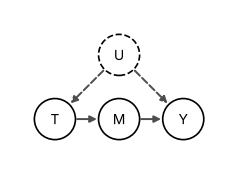

backdoor sets for T -> Y: []
rule 2: P(M | do(T)) = P(M | T)?                  True
rule 2: P(Y | do(M), T) = P(Y | M, T)?             True
rule 3: P(T | do(M)) = P(T)?                       True
rule 3: P(Y | do(T), do(M)) = P(Y | do(M))?        True
rule 2 without conditioning on T (should fail):    False


In [6]:
F = DAG([("U", "T"), ("U", "Y"), ("T", "M"), ("M", "Y")], latent={"U"})
fig, ax = plt.subplots(figsize=(4, 2)); F.draw(ax, {"U": (1, 1), "T": (0, 0), "M": (1, 0), "Y": (2, 0)}); plt.show()
print("backdoor sets for T -> Y:", F.backdoor_sets("T", "Y"))
print("rule 2: P(M | do(T)) = P(M | T)?                 ", docalc.rule2(F, "M", "T"))
print("rule 2: P(Y | do(M), T) = P(Y | M, T)?            ", docalc.rule2(F, "Y", "M", Z="T"))
print("rule 3: P(T | do(M)) = P(T)?                      ", docalc.rule3(F, "T", "M"))
print("rule 3: P(Y | do(T), do(M)) = P(Y | do(M))?       ", docalc.rule3(F, "Y", "T", X="M"))
print("rule 2 without conditioning on T (should fail):   ", docalc.rule2(F, "Y", "M"))

In [7]:
front = SCM(
    equations={
        "U": lambda v, u: u,
        "T": lambda v, u: (u < 0.2 + 0.6 * v["U"]).astype(float),
        "M": lambda v, u: (u < 0.1 + 0.7 * v["T"]).astype(float),
        "Y": lambda v, u: (u < 0.1 + 0.4 * v["M"] + 0.4 * v["U"]).astype(float),
    },
    noise={"U": bernoulli(0.5), "T": uniform(), "M": uniform(), "Y": uniform()},
)
o = front.sample(400_000, seed=5)
T_, M_, Y_ = o["T"], o["M"], o["Y"]
P = lambda m: m.mean()
def front_door(t):
    return sum(P(M_[T_ == t] == m) * sum(P(Y_[(M_ == m) & (T_ == tp)]) * P(T_ == tp) for tp in (0, 1)) for m in (0, 1))
for t in (0, 1):
    print(f"t = {t}:  P(Y=1|T=t) = {P(Y_[T_ == t]):.3f}   front-door = {front_door(t):.3f}   "
          f"P(Y=1|do(T=t)) simulated = {front.sample(400_000, do={'T': t}, seed=6)['Y'].mean():.3f}")

t = 0:  P(Y=1|T=t) = 0.220   front-door = 0.340   P(Y=1|do(T=t)) simulated = 0.339
t = 1:  P(Y=1|T=t) = 0.739   front-door = 0.621   P(Y=1|do(T=t)) simulated = 0.621


## 6. The same observational distribution, different interventions

Two SCMs over binary $(T, Y)$: in the first, $T$ causes $Y$; in the second, a hidden $S$ causes both and $T$ has no
effect at all. They are tuned to produce **exactly the same** joint distribution of $(T, Y)$, so no amount of
observational data can tell them apart. Intervening tells them apart immediately.

In [8]:
causal = SCM({"T": lambda v, u: (u < 0.5).astype(float),
              "Y": lambda v, u: (u < 0.2 + 0.6 * v["T"]).astype(float)},
             {"T": uniform(), "Y": uniform()})
confounded = SCM({"S": lambda v, u: (u < 0.5).astype(float),
                  "T": lambda v, u: v["S"],
                  "Y": lambda v, u: (u < 0.2 + 0.6 * v["S"]).astype(float)},
                 {"S": uniform(), "T": uniform(), "Y": uniform()})
for name, m in [("T -> Y", causal), ("T <- S -> Y", confounded)]:
    o = m.sample(400_000, seed=7)
    joint = [np.mean((o["T"] == t) & (o["Y"] == y)) for t in (0, 1) for y in (0, 1)]
    do1 = m.sample(400_000, do={"T": 1}, seed=8)["Y"].mean()
    do0 = m.sample(400_000, do={"T": 0}, seed=8)["Y"].mean()
    print(f"{name:>12}: P(T,Y) = {np.round(joint, 3)}   P(Y=1|do(T=1)) = {do1:.3f}   P(Y=1|do(T=0)) = {do0:.3f}")

      T -> Y: P(T,Y) = [0.4   0.101 0.1   0.4  ]   P(Y=1|do(T=1)) = 0.800   P(Y=1|do(T=0)) = 0.199


 T <- S -> Y: P(T,Y) = [0.4   0.101 0.1   0.4  ]   P(Y=1|do(T=1)) = 0.499   P(Y=1|do(T=0)) = 0.499


This is the separation between the first two rungs of the ladder: assumptions (a graph) are unavoidable for causal
inference from observational data.

## 7. Counterfactuals: the third rung

An experiment tells us $P(Y(1) = 1)$ and $P(Y(0) = 1)$ separately. Some questions need the **joint** distribution of
both potential outcomes of the same unit, which no experiment observes:

* probability of necessity $\text{PN} = P(Y(0)=0 \mid T=1, Y=1)$: "given it happened under the cause, would removing the
  cause have prevented it?" (legal attribution),
* probability of sufficiency $\text{PS} = P(Y(1)=1 \mid T=0, Y=0)$,
* probability of necessity and sufficiency $\text{PNS} = P(Y(1)=1, Y(0)=0)$.

In an SCM a unit *is* its noise vector, so counterfactuals are computed by evaluating the equations twice with the same
noise. Below, two SCMs with the **same interventional distributions** (both: $P(Y=1|do(T=1)) = 0.7$,
$P(Y=1|do(T=0)) = 0.4$) but different mechanisms: in one, treatment only ever helps ("monotone"); in the other it
helps some units and harms others.

In [9]:
monotone = SCM({"T": lambda v, u: (u < 0.5).astype(float),
                "Y": lambda v, u: (u < 0.4 + 0.3 * v["T"]).astype(float)},      # same u: Y(1) >= Y(0)
               {"T": uniform(), "Y": uniform()})
mixed = SCM({"T": lambda v, u: (u < 0.5).astype(float),
             "Y": lambda v, u: np.where(v["T"] == 1, u < 0.7, u >= 0.6).astype(float)},  # Y(0) uses the other tail
            {"T": uniform(), "Y": uniform()})
p1 = p0 = None
for name, m in [("monotone", monotone), ("helps some, harms some", mixed)]:
    cf = m.counterfactual(400_000, {"do1": {"T": 1}, "do0": {"T": 0}}, seed=9)
    p1, p0 = cf["do1"]["Y"].mean(), cf["do0"]["Y"].mean()
    pr = probabilities_of_causation(cf["do1"]["Y"], cf["do0"]["Y"], cf["factual"]["T"], cf["factual"]["Y"])
    print(f"{name:>24}: P(Y|do(1)) = {p1:.3f}, P(Y|do(0)) = {p0:.3f}  |  PNS = {pr['PNS']:.3f}, PN = {pr['PN']:.3f}, PS = {pr['PS']:.3f}")
lo, hi = pns_bounds(0.7, 0.4)
print(f"\nbounds on PNS from the experiment alone: {lo:.2f} <= PNS <= {hi:.2f}")

                monotone: P(Y|do(1)) = 0.701, P(Y|do(0)) = 0.400  |  PNS = 0.301, PN = 0.431, PS = 0.501


  helps some, harms some: P(Y|do(1)) = 0.701, P(Y|do(0)) = 0.399  |  PNS = 0.601, PN = 0.857, PS = 1.000

bounds on PNS from the experiment alone: 0.30 <= PNS <= 0.60


Identical experiments, different PNS: the counterfactual rung is separated from the interventional one just as the
interventional is from the observational. Experimental data still constrain it, through the bounds
$\max(0, P(y|do(1)) - P(y|do(0))) \le \text{PNS} \le \min(P(y|do(1)), P(y'|do(0)))$, and the two SCMs sit at its two ends
(the monotone one at the lower bound, since monotonicity makes PNS equal to the ATE; the other at the upper bound). Extra assumptions such as
monotonicity are what turn bounds into point identification.

## What carries over

* The backdoor criterion is the graphical form of conditional ignorability: it says *which* covariates to put in the
  regressions, propensity models and nuisance models of [02](../../../02-regression/)–[08](../../../08-orthogonal-learning/).
* When no backdoor set exists, do-calculus can still identify the effect (front door), and
  [instrumental variables](../../../10-instruments-and-discontinuities/) are another graphical escape route.
* PNS reappears in [07](../../../07-causal-deep-learning/) as a training objective for causal representations
  (Wang & Jordan 2024).